# Exploración de datos de atún

Esta base contiene registros de captura y esfuerzo pesquero
de atunes en el Pacífico oriental entre 1958 y 2025.

In [8]:
from pathlib import Path

print("Carpeta de trabajo:", Path.cwd())

for archivo in Path(".").glob("*.csv"):
    print(archivo.name)

Carpeta de trabajo: /home/jovyan
Ballena_Jorobada_Pacifico_Norte_2025-2026.csv
PublicPSTunaSetType.csv
atun_aleta_amarilla_region.csv
atun_domo_aleta_amarilla.csv


In [9]:
import pandas as pd

datos = pd.read_csv("PublicPSTunaSetType.csv")

datos.head(6)

,Year,Month,SetType,LatC1,LonC1,NumSets,ALB,BET,BKJ,BZX,FRZ,PBF,SKJ,TUN,YFT
0,1958,12,NOA,18.5,-114.5,8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,26.3
1,1958,12,NOA,18.5,-110.5,10,0.0,0.0,0.0,0.0,0.0,0.0,54.4,0.0,0.0
2,1958,12,NOA,19.5,-110.5,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.1
3,1959,1,NOA,15.5,-97.5,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,99.9
4,1959,1,NOA,16.5,-100.5,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,1959,1,DEL,16.5,-99.5,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.4


In [10]:
#crear el subset para C.R 
atun_region = datos[
    (datos["LatC1"] >= 7) &
    (datos["LatC1"] <= 12) &
    (datos["LonC1"] >= -89) &
    (datos["LonC1"] <= -82)
]

# Mostrar las primeras seis filas
atun_region.head(6)

,Year,Month,SetType,LatC1,LonC1,NumSets,ALB,BET,BKJ,BZX,FRZ,PBF,SKJ,TUN,YFT
141,1959,8,NOA,9.5,-85.5,4,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,27.20
198,1959,10,NOA,9.5,-85.5,76,0.0,0.0,0.0,0.0,0.0,0.0,42.87,0.0,299.12
199,1959,10,DEL,9.5,-84.5,1,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,27.20
200,1959,10,DEL,10.5,-86.5,1,0.0,0.0,0.0,0.0,0.0,0.0,9.10,0.0,18.10
201,1959,10,NOA,10.5,-86.5,1,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00
202,1959,10,NOA,11.5,-87.5,5,0.0,0.0,0.0,0.0,0.0,0.0,1.80,0.0,2.70


## Descripción de las columnas

- **Year:** año de la actividad pesquera.
- **Month:** mes, de 1 (enero) a 12 (diciembre).
- **SetType:** tipo de lance de pesca:
  - **DEL:** sobre atunes asociados con delfines.
  - **NOA:** sobre cardúmenes no asociados con delfines ni objetos flotantes.
  - **OBJ:** sobre atunes asociados con objetos flotantes.
- **LatC1:** latitud del centro de la cuadrícula; los valores positivos indican norte.
- **LonC1:** longitud del centro de la cuadrícula; los valores negativos indican oeste.
- **NumSets:** número de lances de pesca agrupados en la fila.
- **ALB:** albacora o atún blanco (*Thunnus alalunga*).
- **BET:** atún patudo (*Thunnus obesus*).
- **BKJ:** barrilete negro (*Euthynnus lineatus*).
- **BZX:** bonitos del género *Sarda*, sin precisar la especie.
- **FRZ:** melvas (*Auxis thazard* y *Auxis rochei*).
- **PBF:** atún aleta azul del Pacífico (*Thunnus orientalis*).
- **SKJ:** barrilete o listado (*Katsuwonus pelamis*).
- **TUN:** atunes no especificados en otra categoría; no es la suma de todos los atunes.
- **YFT:** atún aleta amarilla (*Thunnus albacares*). 

Cada fila agrupa datos por año, mes, cuadrícula de 1° × 1° y tipo de lance.

Fuente: https://www.iattc.org/es-es/Data/Reference-codes

In [11]:
# subset de datos para atún aleta amarilla
atun_aleta_amarilla = atun_region[
    ["Year", "Month", "SetType", "LatC1", "LonC1", "NumSets", "YFT"]
].copy()

# Mostrar las primeras seis filas
atun_aleta_amarilla.head(6)

,Year,Month,SetType,LatC1,LonC1,NumSets,YFT
141,1959,8,NOA,9.5,-85.5,4,27.20
198,1959,10,NOA,9.5,-85.5,76,299.12
199,1959,10,DEL,9.5,-84.5,1,27.20
200,1959,10,DEL,10.5,-86.5,1,18.10
201,1959,10,NOA,10.5,-86.5,1,0.00
202,1959,10,NOA,11.5,-87.5,5,2.70


- NumSets indica cuántos lances se realizaron en ese año, mes, cuadrícula y tipo de lance.
- YFT indica la captura de aleta amarilla correspondiente a esos lances.
Por ejemplo, si NumSets = 4 y YFT = 20, se registraron 20 toneladas
de aleta amarilla en cuatro lances. La captura promedio fue de
5 toneladas por lance.

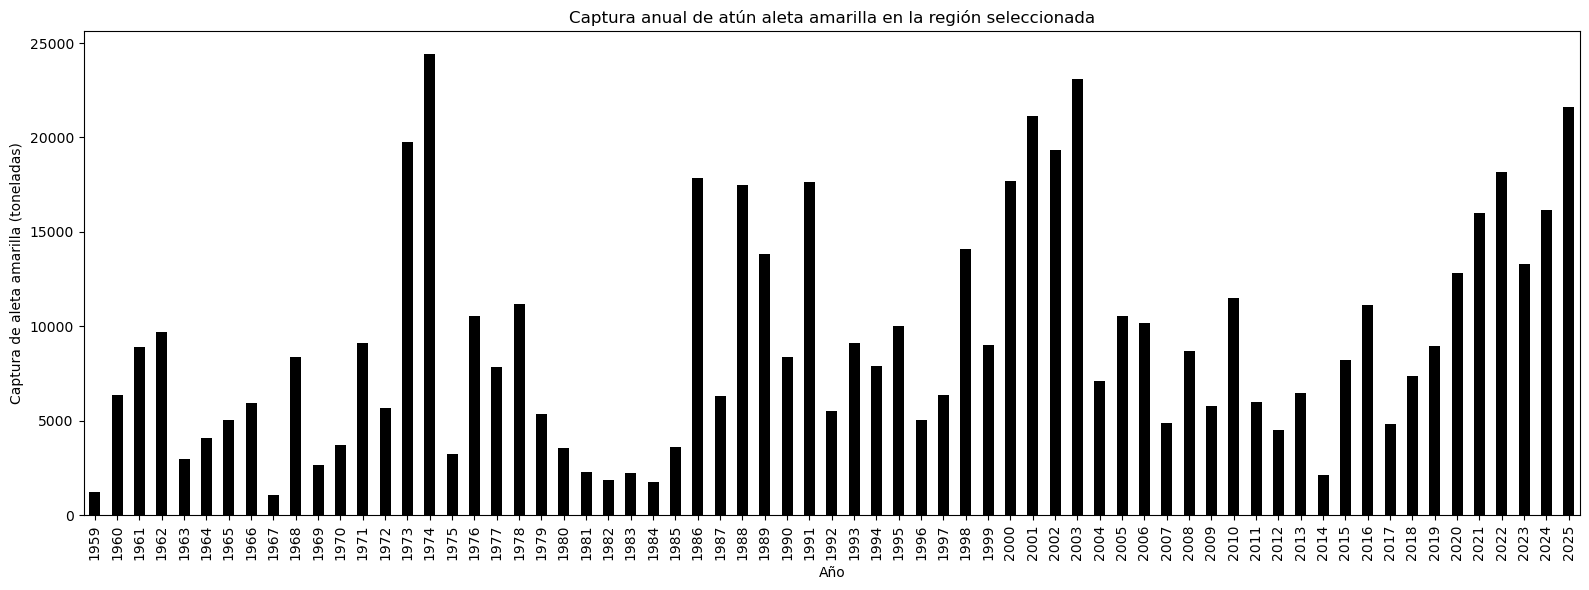

In [12]:
import matplotlib.pyplot as plt

# Sumar las toneladas capturadas por año
captura_anual = atun_aleta_amarilla.groupby("Year")["YFT"].sum()

# Crear el gráfico de barras
captura_anual.plot(kind="bar", figsize=(16, 6), color="black")

plt.xlabel("Año")
plt.ylabel("Captura de aleta amarilla (toneladas)")
plt.title("Captura anual de atún aleta amarilla en la región seleccionada")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [13]:
atun_aleta_amarilla.to_csv("atun_aleta_amarilla_region.csv", index=False)

## Propuesta de delimitación del área de estudio

**7° y 11° de latitud norte** y **87° y 93° de longitud oeste**, esto tomando como referencia la extensión del núcleo climatológico del Domo Térmico de Costa Rica descrita por Shi y Wang (2024).

Este rectángulo se utiliza como un área fija para comparar las capturas entre años, pero no representa el límite exacto del Domo en cada fecha, ya que su posición y extensión varían.

## Selección de los datos pesqueros

Entonces a partir de la base completa de la CIAT, se seleccionaron los registros cuyos centros de cuadrícula se encuentran dentro del área definida y se conservaron el año, el mes, el tipo de lance, las coordenadas, el número de lances y la captura de atún aleta amarilla (*Thunnus albacares*).


## Referencia

Shi, W., & Wang, M. (2024). Ocean variability in the Costa Rica Thermal Dome region from 2012 to 2021. *Remote Sensing, 16*(8), 1340. https://doi.org/10.3390/rs16081340

In [14]:
# Seleccionar entre 7–11° norte y 87–93° oeste
atun_domo = datos[
    (datos["LatC1"] >= 7) &
    (datos["LatC1"] <= 11) &
    (datos["LonC1"] >= -93) &
    (datos["LonC1"] <= -87)
].copy()

In [15]:
atun_domo = atun_domo[
    ["Year", "Month", "SetType", "LatC1", "LonC1", "NumSets", "YFT"]
].copy()

In [16]:
atun_domo.head(6)

,Year,Month,SetType,LatC1,LonC1,NumSets,YFT
510,1960,4,DEL,10.5,-89.5,5,86.1
581,1960,5,DEL,9.5,-90.5,3,63.5
582,1960,5,DEL,9.5,-89.5,1,18.1
585,1960,5,DEL,10.5,-90.5,1,22.7
586,1960,5,DEL,10.5,-89.5,14,399.1
587,1960,5,DEL,10.5,-88.5,4,33.6


In [17]:
atun_domo.to_csv("atun_domo_aleta_amarilla.csv", index=False)

In [18]:
# Agrupar por coordenadas y sumar los lances
lances_mapa = atun_domo.groupby(
    ["LatC1", "LonC1"]
)["NumSets"].sum().reset_index()

lances_mapa.head(6)

,LatC1,LonC1,NumSets
0,7.5,-92.5,1970
1,7.5,-91.5,1921
2,7.5,-90.5,2470
3,7.5,-89.5,2455
4,7.5,-88.5,2189
5,7.5,-87.5,2249


In [22]:
import json
from urllib.request import urlopen
from urllib.parse import urlencode

# Cargar las zonas económicas exclusivas
servicio = (
    "https://services3.arcgis.com/2LJ6Q6yCIIUOP8qx/"
    "ArcGIS/rest/services/eez_v12/FeatureServer/0/query"
)

consulta = {
    "where": "ISO_TER1 IN ('CRI','NIC','PAN') AND POL_TYPE = '200NM'",
    "outFields": "GEONAME",
    "returnGeometry": "true",
    "outSR": 4326,
    "maxAllowableOffset": 0.01,
    "f": "geojson"
}

url = servicio + "?" + urlencode(consulta)

with urlopen(url) as respuesta:
    limites_marinos = json.load(respuesta)

print("Zonas cargadas:", len(limites_marinos["features"]))

# Sumar los lances por cuadrícula
lances_mapa = atun_domo.groupby(
    ["LatC1", "LonC1"]
)["NumSets"].sum().reset_index()

Zonas cargadas: 3


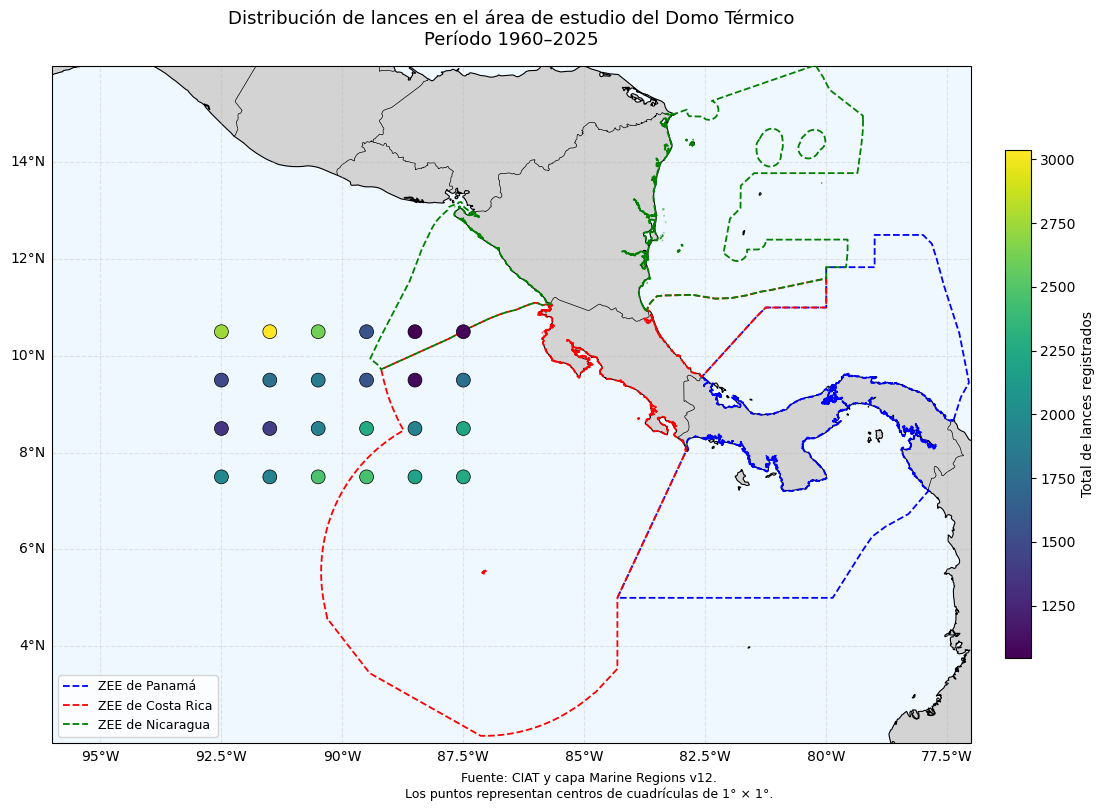

In [23]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Crear el mapa
fig, ax = plt.subplots(
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

ax.set_extent([-96, -77, 2, 16], crs=ccrs.PlateCarree())

# Océano, tierra y fronteras
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=1)
ax.coastlines(linewidth=0.8, zorder=2)
ax.add_feature(cfeature.BORDERS, linewidth=0.5, zorder=2)

# Nombres y colores de los países
nombres = {
    "Panamanian Exclusive Economic Zone": "ZEE de Panamá",
    "Costa Rican Exclusive Economic Zone": "ZEE de Costa Rica",
    "Nicaraguan Exclusive Economic Zone": "ZEE de Nicaragua"
}

colores = {
    "Panamanian Exclusive Economic Zone": "blue",
    "Costa Rican Exclusive Economic Zone": "red",
    "Nicaraguan Exclusive Economic Zone": "green"
}

# Dibujar los límites marítimos
for zona in limites_marinos["features"]:

    nombre = zona["properties"]["GEONAME"]
    geometria = zona["geometry"]

    if geometria["type"] == "Polygon":
        poligonos = [geometria["coordinates"]]
    else:
        poligonos = geometria["coordinates"]

    for numero, poligono in enumerate(poligonos):

        contorno = poligono[0]
        x = [punto[0] for punto in contorno]
        y = [punto[1] for punto in contorno]

        # El servicio consultado devuelve coordenadas en metros.
        # Si devuelve grados, se reconoce por sus valores.
        if max(abs(valor) for valor in x) > 180:
            sistema = ccrs.epsg(3857)
        else:
            sistema = ccrs.PlateCarree()

        ax.plot(
            x, y,
            color=colores[nombre],
            linewidth=1.3,
            linestyle="--",
            transform=sistema,
            label=nombres[nombre] if numero == 0 else None,
            zorder=4
        )

# Dibujar los puntos: centros de las cuadrículas pesqueras
puntos = ax.scatter(
    lances_mapa["LonC1"],
    lances_mapa["LatC1"],
    c=lances_mapa["NumSets"],
    cmap="viridis",
    s=100,
    edgecolors="black",
    linewidths=0.5,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# Barra de colores
fig.colorbar(
    puntos,
    ax=ax,
    label="Total de lances registrados",
    shrink=0.75,
    pad=0.03
)

# Coordenadas del mapa
rejilla = ax.gridlines(
    draw_labels=True,
    alpha=0.3,
    linestyle="--"
)

rejilla.top_labels = False
rejilla.right_labels = False

# Período representado
inicio = int(atun_domo["Year"].min())
fin = int(atun_domo["Year"].max())

ax.set_title(
    f"Distribución de lances en el área de estudio del Domo Térmico\n"
    f"Período {inicio}–{fin}",
    fontsize=13,
    pad=15
)

ax.legend(loc="lower left", fontsize=9)

fig.text(
    0.5, 0.03,
    "Fuente: CIAT y capa Marine Regions v12.\n"
    "Los puntos representan centros de cuadrículas de 1° × 1°.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

In [26]:
import pandas as pd

roni = pd.read_csv("RONI.ascii.txt", sep=r"\s+")

roni.head(6)

,SEAS,YR,ANOM
0,DJF,1950,-1.19
1,JFM,1950,-1.08
2,FMA,1950,-0.96
3,MAM,1950,-1.00
4,AMJ,1950,-0.99
5,MJJ,1950,-0.75


In [27]:
# Contar los registros disponibles por año
registros_por_anio = atun_domo.groupby("Year").size()

registros_por_anio

Year
1960     11
1961     33
1962     41
1963     20
1964     77
       ... 
2021    106
2022     92
2023    115
2024     62
2025     72
Length: 66, dtype: int64

In [1]:
# Descargar datos de SST de Marine Copernicus para la región del Domo Térmico | Hace falta registrarse por que pide usuario y contraseña
import copernicusmarine
copernicusmarine.subset(
  dataset_id="cmems_obs-ins_glo_phy-temp-sal_my_cora-oa_P1M",
  variables=["TEMP"],
  minimum_longitude=-96,
  maximum_longitude=-77,
  minimum_latitude=2,
  maximum_latitude=16,
  start_datetime="1960-01-01T00:00:00",
  end_datetime="2025-06-01T00:00:00",
  minimum_depth=1,
  maximum_depth=1,
)

/home/gsus/miniconda3/envs/mcopernicus/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO - 2026-11-18T21:09:47Z - Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register
INFO - 2026-11-18T21:14:42Z - Selected dataset version: "202603"
INFO - 2026-11-18T21:14:42Z - Selected dataset part: "default"
WARNING - 2026-11-18T21:14:42Z - You are using the dataset cmems_obs-ins_glo_phy-temp-sal_my_cora-oa_P1M, version '202603', part 'default'. This exact version and part of the dataset will be retired on the 2026-11-24T13:00:00.000Z. For more information you can check: https://marine.copernicus.eu/user-corner/product-roadmap/transition-information
100%|██████████| [00:06<00:00]
INFO - 2026-11-18T21:14:52Z - Total siz

ResponseSubset(file_path=PosixPath('cmems_obs-ins_glo_phy-temp-sal_my_cora-oa_P1M_TEMP_96.00W-77.00W_2.10N-16.00N_1.00m_1960-01-01-2025-06-01_(1).nc'), output_directory=PosixPath('.'), filename='cmems_obs-ins_glo_phy-temp-sal_my_cora-oa_P1M_TEMP_96.00W-77.00W_2.10N-16.00N_1.00m_1960-01-01-2025-06-01_(1).nc', file_size=16.393, data_transfer_size=176.72207633587786, variables=['TEMP'], coordinates_extent=[GeographicalExtent(minimum=-96.0, maximum=-77.0, unit='degrees_east', coordinate_id='longitude'), GeographicalExtent(minimum=2.0999999999955037, maximum=15.999999999994714, unit='degrees_north', coordinate_id='latitude'), TimeExtent(minimum='1960-01-01T00:00:00+00:00', maximum='2025-06-01T00:00:00+00:00', unit='iso8601', coordinate_id='time'), GeographicalExtent(minimum=1.0, maximum=1.0, unit='m', coordinate_id='depth')], status='000', message='The request was successful.', file_status='DOWNLOADED', file_names=None)

<xarray.Dataset> Size: 17MB
Dimensions:    (time: 786, depth: 1, latitude: 140, longitude: 39)
Coordinates:
  * depth      (depth) float32 4B 1.0
  * latitude   (latitude) float64 1kB 2.1 2.2 2.3 2.4 ... 15.7 15.8 15.9 16.0
  * longitude  (longitude) float64 312B -96.0 -95.5 -95.0 ... -78.0 -77.5 -77.0
  * time       (time) datetime64[ns] 6kB 1960-01-01 1960-02-01 ... 2025-06-01
Data variables:
    TEMP       (time, depth, latitude, longitude) float32 17MB ...
Attributes: (12/22)
    Conventions:               CF-1.4
    analysis_name:             OA_CORA5.2_
    comment:                   V8.0 reference climatology and analysis parame...
    creation_date:             20260511T073736
    data_manager:              Tanguy Szekely
    easternmost_longitude:     179.5
    ...                        ...
    southernmost_latitude:     -77.010475
    start_date:                2025-06-15
    stop_date:                 2025-06-15
    title:                     Global Ocean - Coriolis Observa

/home/gsus/anaconda3/envs/spyder_env/lib/python3.12/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


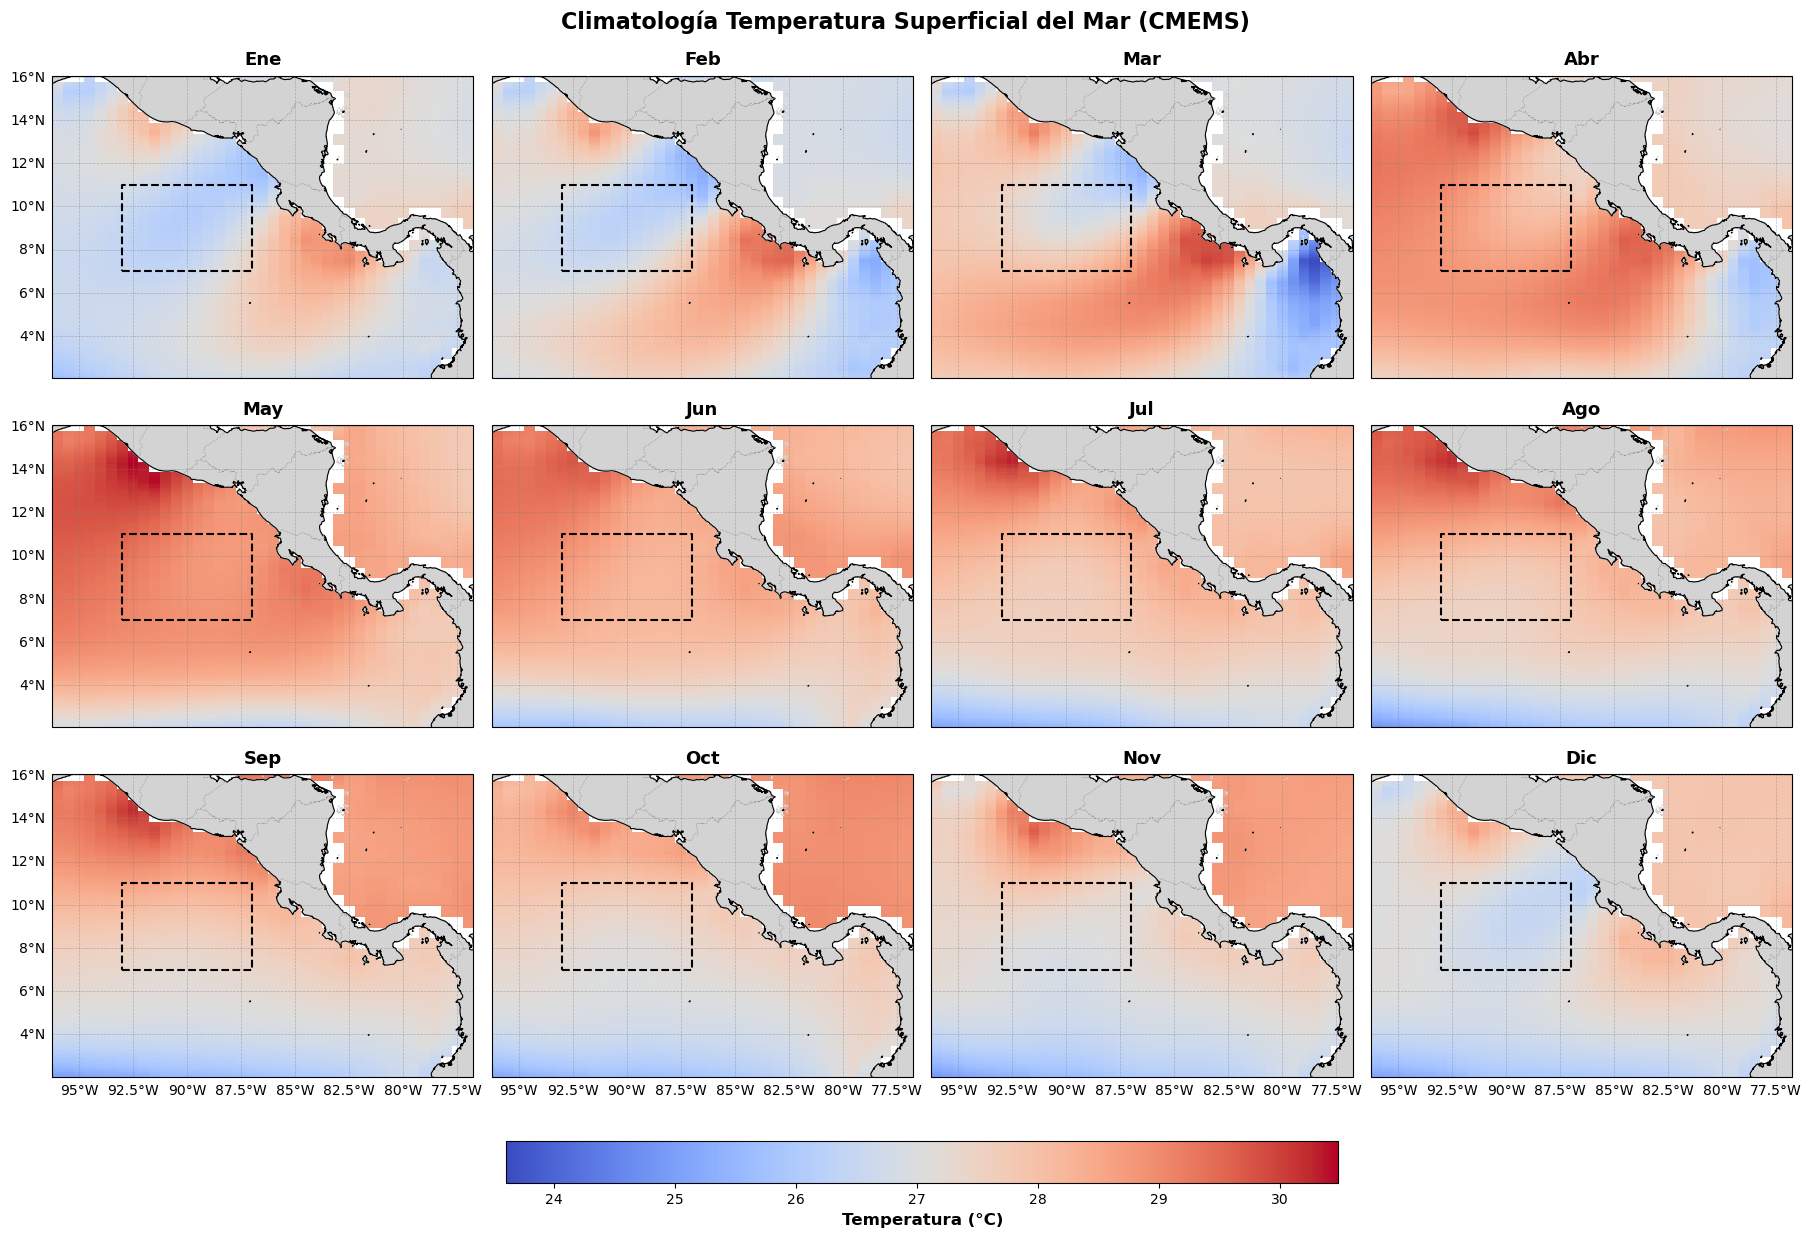

In [1]:

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Abrir el archivo NetCDF de CMEMS
#archivo_nc = '/home/gsus/gdrive/GitHub/ohw/ohw26_week2/OHWE_26_ATUN_TEMP/cmems_obs-ins_glo_phy-temp-sal_my_cora-oa_P1M_TEMP_96.00W-77.00W_2.10N-16.00N_1.00m_1960-01-01-2025-06-01.nc'
archivo_nc = 'cmems_obs-ins_glo_phy-temp-sal_my_cora-oa_P1M_TEMP_96.00W-77.00W_2.10N-16.00N_1.00m_1960-01-01-2025-06-01.nc'

ds = xr.open_dataset(archivo_nc)
print(ds)
var_temp = 'TEMP'

# Seleccionar la superficie (depth = 0) para eliminar esa dimensión
# Agrupar por mes para crear la climatología promedio de cada mes
climatologia_mensual = ds[var_temp].isel(depth=0).groupby('time.month').mean(dim='time')

# Coordenadas y límites globales para fijar la colorbar
vmin = climatologia_mensual.min().item()
vmax = climatologia_mensual.max().item()
# Vector con nombres de los meses en castellano y 3 letras
month_names = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 
               'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
# Límites del recuadro (Domo)
lon_min, lon_max = -93, -87
lat_min, lat_max = 7, 11

# %% f(x) para graficar la climatología (3x4) con cartopy
def plot_grid_3x4_cartopy(data_3d, title_text, cbar_label, cmap, 
                          limite_lat=None, limite_lon=None, divergent=False):
    # Figura 3x4 con proyección cartográfica en cada subplot
    fig, axes = plt.subplots(
        nrows=3,
        ncols=4,
        figsize=(18, 12),
        subplot_kw={'projection': ccrs.PlateCarree()},
        constrained_layout=True,
    )
    axes_flat = axes.flatten()

    if divergent:
        max_val = np.nanmax(np.abs(data_3d.values))
        vmin_val, vmax_val = -max_val, max_val
    else:
        vmin_val, vmax_val = data_3d.min().item(), data_3d.max().item()

    for i in range(12):
        ax = axes_flat[i]
        data_2d = data_3d.isel(month=i).values

        # Graficar mapa espacial
        im = ax.pcolormesh(
            data_3d.longitude, data_3d.latitude, data_2d,
            cmap=cmap, vmin=vmin_val, vmax=vmax_val,
            shading='auto', transform=ccrs.PlateCarree()
        )

        # Capas geográficas de Cartopy
        ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='face', zorder=2)
        ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.8, zorder=3)
        ax.add_feature(cfeature.BORDERS, linestyle=':', edgecolor='gray', linewidth=0.5, zorder=3)

        # Grilla (meridianos y paralelos) con etiquetas automáticas
        gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
        gl.top_labels = False
        gl.right_labels = False
        if i % 4 != 0:
            gl.left_labels = False
        if i < 8:
            gl.bottom_labels = False

        # Dibujar el rectángulo del domo
        if limite_lat and limite_lon:
            rect_lons = [limite_lon[0], limite_lon[1], limite_lon[1], limite_lon[0], limite_lon[0]]
            rect_lats = [limite_lat[0], limite_lat[0], limite_lat[1], limite_lat[1], limite_lat[0]]
            ax.plot(
                rect_lons, rect_lats,
                color='black', linewidth=1.5, linestyle='--',
                transform=ccrs.PlateCarree(), zorder=4
            )

        # Título del mes
        ax.set_title(month_names[i], fontsize=13, fontweight='bold', pad=8)

    # Barra de colores horizontal compartida abajo
    cbar = fig.colorbar(
        im, ax=axes, orientation='horizontal', fraction=0.04, pad=0.04, shrink=0.6
    )
    cbar.set_label(cbar_label, fontsize=12, fontweight='bold')
    plt.suptitle(title_text, fontsize=16, fontweight='bold', y=1.02)
    plt.show()
# 
# %% Figura
plot_grid_3x4_cartopy(
    data_3d=climatologia_mensual,
    title_text='Climatología Temperatura Superficial del Mar (CMEMS)',
    cbar_label='Temperatura (°C)',
    cmap='coolwarm',
    limite_lat=(lat_min, lat_max),
    limite_lon=(lon_min, lon_max),
    divergent=False
)
# %% Cerrar dataset al finalizar
ds.close()

In [52]:
import numpy as np
import xarray as xr

# Seleccionar la variable de temperatura
var_temp = "TEMP"

# Reconstruir la climatología utilizada por tu compañero
climatologia_mensual = (
    ds[var_temp]
    .isel(depth=0)
    .groupby("time.month")
    .mean(dim="time")
)

print(climatologia_mensual.sizes)

Frozen({'month': 12, 'latitude': 140, 'longitude': 39})


In [53]:
print(ds)
# --- A. Para hacer EOF, primero calculamos las anomalías y eliminamos la tendencia lineal ---
# 1. Calculo de anomalías mensuales (dimensión: time, lat, lon)
sst_anom = ds[var_temp].isel(depth=0).groupby('time.month') - climatologia_mensual 
# 2. Eliminar la tendencia lineal (detrending)
# Convertimos el tiempo a formato numérico para el ajuste de xarray
# Ajustamos un polinomio de grado 1 (recta) en cada punto de rejilla
poly_fit = sst_anom.polyfit(dim="time", deg=1)
# 3. Calculamos la línea de tendencia basada en el ajuste
trend_line = xr.polyval(sst_anom.time, poly_fit.polyfit_coefficients)
# 4. Restamos la tendencia para obtener los datos finales
sst_final = sst_anom - trend_line

# --- B. EOF ---
#from eofs.xarray import Eof
from eofs.standard import Eof
# Pesos por latitud: sqrt(cos(lat)) para tener en cuenta el área de cada banda de latitud
coslat = np.cos(np.deg2rad(sst_final.latitude.values))
wgts = np.sqrt(coslat) #pesos
# Expandir a 2D: lat × lon
wgts_2d = np.repeat(wgts[:, np.newaxis], sst_final.longitude.size, axis=1)
# Aseguramos el orden (time, latitude, longitude) ya que eofs.standard.Eof asume por defecto que el eje 0 es time
sst_final = sst_final.transpose("time", "latitude", "longitude")
# Calculamos EOF convirtiendo el array a Numpy con .values
solver = Eof(sst_final.values, weights=wgts_2d)

cant_modos = 2
scaling_pc_adim = 1       # pcscaling
scaling_eof = 2           # eofscaling
#Se pueden chequear en la documentación de la librería las distintas opciones de scaling
eof = solver.eofs(neofs=cant_modos, eofscaling=scaling_eof)   # (modo, lat, lon)
pc = solver.pcs(npcs=cant_modos, pcscaling=scaling_pc_adim)  # (time, modo)
varfrac = solver.varianceFraction()   # (modo,)

print(f'Estructura de EOF (cantidad de modos, latitud, longitud): {eof.shape}')

eof1 = xr.DataArray(
    eof[0,::],
    coords={"lat": sst_final.latitude, "lon": sst_final.longitude},
    dims=["latitude", "longitude"],
    name="EOF1"
)

pc1 = xr.DataArray(
    pc[:,0],
    coords={"time": sst_final.time},
    dims=["time"],
    name="PC1"
)

print(f"Varianza explicada por el modo 1: {varfrac[0]*100:.1f}%")
print(f"Varianza explicada por el modo 2: {varfrac[1]*100:.1f}%")

<xarray.Dataset> Size: 17MB
Dimensions:    (time: 786, depth: 1, latitude: 140, longitude: 39)
Coordinates:
  * time       (time) datetime64[ns] 6kB 1960-01-01 1960-02-01 ... 2025-06-01
  * depth      (depth) float32 4B 1.0
  * latitude   (latitude) float64 1kB 2.1 2.2 2.3 2.4 ... 15.7 15.8 15.9 16.0
  * longitude  (longitude) float64 312B -96.0 -95.5 -95.0 ... -78.0 -77.5 -77.0
Data variables:
    TEMP       (time, depth, latitude, longitude) float32 17MB ...
Attributes: (12/22)
    Conventions:               CF-1.4
    analysis_name:             OA_CORA5.2_
    comment:                   V8.0 reference climatology and analysis parame...
    creation_date:             20260511T073736
    data_manager:              Tanguy Szekely
    easternmost_longitude:     179.5
    ...                        ...
    southernmost_latitude:     -77.010475
    start_date:                2025-06-15
    stop_date:                 2025-06-15
    title:                     Global Ocean - Coriolis Observa

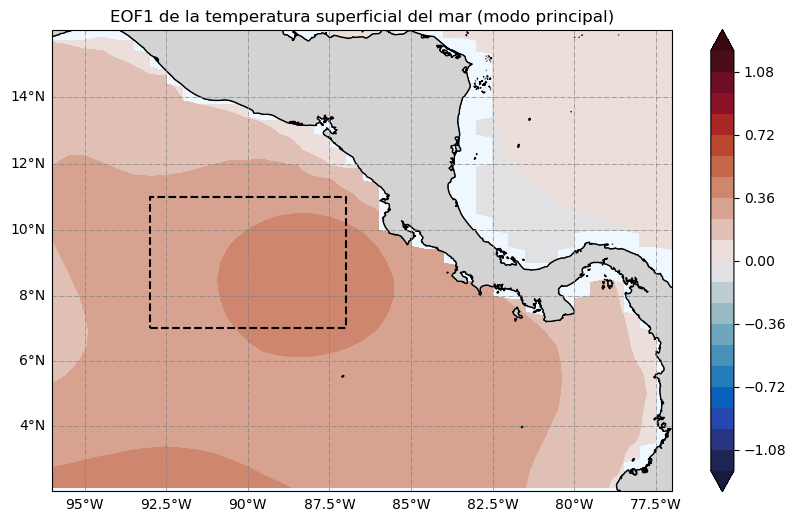

Número de meses en fase positiva: 105
Número de meses en fase negativa: 87


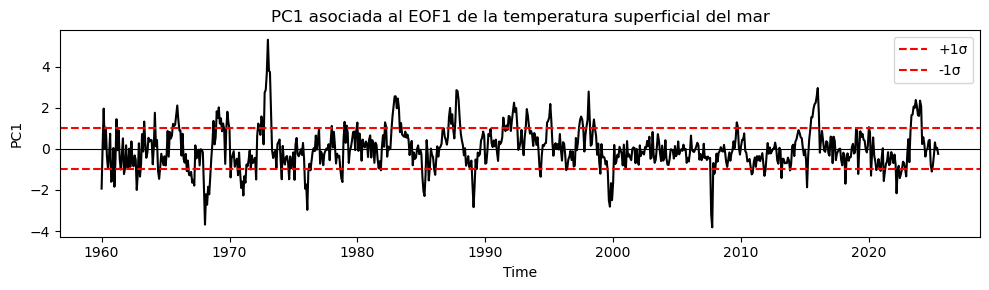

In [ ]:
# Gráfico de EOF sst y definición de fases del modo 1
import cmocean
lon = eof1.lon
lat = eof1.lat

# Campo espacial EOF1
fig = plt.figure(figsize=(10,6))
ax = plt.subplot(111, projection=ccrs.Mercator())
ax.set_extent([-96, -77, 2, 16], crs=ccrs.PlateCarree())

# Océano, tierra y fronteras
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=1)
ax.coastlines(linewidth=0.8, zorder=2)
ax.add_feature(cfeature.BORDERS, linewidth=0.5, zorder=2)
# Dibujar el rectángulo del domo
rect_lons = [lon_min, lon_max, lon_max, lon_min, lon_min]
rect_lats = [lat_min, lat_min, lat_max, lat_max, lat_min]
ax.plot(
    rect_lons, rect_lats,
    color='black', linewidth=1.5, linestyle='--',
    transform=ccrs.PlateCarree(), zorder=4
        )

ax.set_title("EOF1 de la temperatura superficial del mar (modo principal)")
levels_contourf = np.linspace(-1.2, 1.2, 21)
cf = ax.contourf(lon, lat, eof1, levels = levels_contourf, transform=ccrs.PlateCarree(),
                 cmap=cmocean.cm.balance, extend='both')
ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', zorder=2)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='grey', linestyle='-.')
gl.top_labels = False
gl.right_labels = False
cb = plt.colorbar(cf, extend="both", orientation='vertical')
plt.show()

# Serie temporal de la PC1
plt.figure(figsize=(10, 3))
pc1.plot(color='k')
std_pc1 = pc1.std(dim='time')
plt.axhline(0, color='k', linewidth=0.8)
plt.axhline(std_pc1, color='r', linestyle='--', label='+1σ')
plt.axhline(-std_pc1, color='r', linestyle='--', label='-1σ')
plt.legend()
plt.title('PC1 asociada al EOF1 de la temperatura superficial del mar')
plt.tight_layout()



Número de meses en fase positiva: 105
['1960-03-01T00:00:00.000000000' '1960-05-01T00:00:00.000000000'
 '1961-03-01T00:00:00.000000000' '1963-05-01T00:00:00.000000000'
 '1964-03-01T00:00:00.000000000'] ... ['2023-10-01T00:00:00.000000000' '2023-11-01T00:00:00.000000000'
 '2023-12-01T00:00:00.000000000' '2024-01-01T00:00:00.000000000'
 '2024-02-01T00:00:00.000000000']
Número de meses en fase negativa: 87
['1960-01-01T00:00:00.000000000' '1960-10-01T00:00:00.000000000'
 '1960-11-01T00:00:00.000000000' '1961-01-01T00:00:00.000000000'
 '1961-07-01T00:00:00.000000000'] ... ['2022-04-01T00:00:00.000000000' '2022-06-01T00:00:00.000000000'
 '2022-07-01T00:00:00.000000000' '2022-12-01T00:00:00.000000000'
 '2024-12-01T00:00:00.000000000']
Número de meses en fase neutra: 594
['1960-02-01T00:00:00.000000000' '1960-04-01T00:00:00.000000000'
 '1960-06-01T00:00:00.000000000' '1960-07-01T00:00:00.000000000'
 '1960-08-01T00:00:00.000000000'] ... ['2025-02-01T00:00:00.000000000' '2025-03-01T00:00:00.000

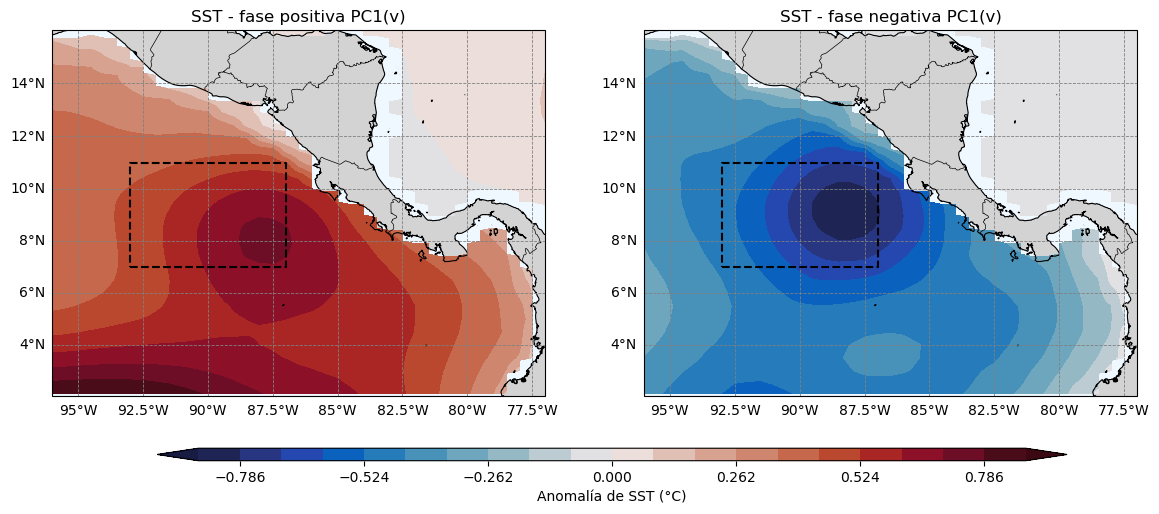

In [58]:
# Definimos fases positiva y negativa del modo 1
pc1_pos = pc1.where(pc1 > std_pc1, drop=True)
pc1_neg = pc1.where(pc1 < -std_pc1, drop=True)
t_pos = pc1_pos['time']
t_neg = pc1_neg['time']

print(f"Número de meses en fase positiva: {t_pos.size}")
print(t_pos.values[:5],f"...", t_pos.values[-5:])
print(f"Número de meses en fase negativa: {t_neg.size}")
print(t_neg.values[:5],f"...", t_neg.values[-5:])

pc1_neu = pc1.where((pc1 >= -std_pc1) & (pc1 <= std_pc1), drop=True)
t_neu = pc1_neu['time']

print(f"Número de meses en fase neutra: {t_neu.size}")
print(t_neu.values[:5],f"...", t_neu.values[-5:])

# Composites de sst 
sst_pos = sst_final.sel(time=t_pos).mean(dim='time')
sst_neg = sst_final.sel(time=t_neg).mean(dim='time')

# Composites de temperatura superficial
vmax_sst = max(abs(float(sst_pos.min())), abs(float(sst_pos.max())))
levels_sst = np.linspace(-vmax_sst, vmax_sst, 21)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5),
    subplot_kw=dict(projection=ccrs.Mercator())
)
for ax, field, titulo in zip(
    axes,
    [sst_pos, sst_neg],
    ['SST - fase positiva PC1(v)', 'SST - fase negativa PC1(v)']
):
    #ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.set_extent([-96, -77, 2, 16], crs=ccrs.PlateCarree())

    # Océano, tierra y fronteras
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=1)
    ax.coastlines(linewidth=0.8, zorder=2)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, zorder=2)
    # Dibujar el rectángulo del domo
    rect_lons = [lon_min, lon_max, lon_max, lon_min, lon_min]
    rect_lats = [lat_min, lat_min, lat_max, lat_max, lat_min]
    ax.plot(
        rect_lons, rect_lats,
        color='black', linewidth=1.5, linestyle='--',
        transform=ccrs.PlateCarree(), zorder=4
    )
    pcm = ax.contourf(
        sst_final['longitude'], sst_final['latitude'], field,
        levels=levels_sst,
        cmap=cmocean.cm.balance,
        extend='both',
        transform=ccrs.PlateCarree()
    )
    ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black')
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=True,
        linewidth=0.6, color='gray', linestyle='--'
    )
    gl.top_labels = False
    gl.right_labels = False
    ax.set_title(titulo)
cbar_ax = fig.add_axes([0.20, 0.0, 0.65, 0.025])
cbar = fig.colorbar(
    pcm, cax=cbar_ax, orientation='horizontal',
    label='Anomalía de SST (°C)'
)
plt.show()

In [49]:
# Comprobar si está cargada la PC1 del análisis 
print("PC1 está disponible:", "pc1" in globals())

PC1 está disponible: False


In [50]:
from eofs.standard import Eof

In [51]:
# Mostrar los primeros seis valores de PC1, si ya está creada
if "pc1" in globals():
    print(pc1.head(6))
else:
    print("PC1 todavía no está creada.")

PC1 todavía no está creada.


In [54]:
# Mostrar los primeros seis valores y sus fechas
print(pc1.head(6))

<xarray.DataArray 'PC1' (time: 6)> Size: 48B
array([-1.93430358,  0.24521558,  1.95405066, -0.00199548,  1.02953697,
       -0.36302223])
Coordinates:
  * time     (time) datetime64[ns] 48B 1960-01-01 1960-02-01 ... 1960-06-01


In [55]:
# Convertir PC1 en una tabla
tabla_fases = pc1.to_dataframe().reset_index()
tabla_fases = tabla_fases.rename(columns={"time": "fecha"})

# Calcular el umbral utilizado por el compañero
umbral = float(pc1.std(dim="time"))

# Clasificar los meses
tabla_fases["fase"] = "Neutra"

tabla_fases.loc[tabla_fases["PC1"] > umbral, "fase"] = "Positiva"
tabla_fases.loc[tabla_fases["PC1"] < -umbral, "fase"] = "Negativa"

# Contar los meses por fase
print(tabla_fases["fase"].value_counts())

fase
Neutra      594
Positiva    105
Negativa     87
Name: count, dtype: int64


In [56]:
# Añadir la fase de PC1 a los meses del análisis
datos_fases = datos_analisis.merge(
    tabla_fases[["fecha", "PC1", "fase"]],
    on="fecha",
    how="inner",
    validate="one_to_one"
)

# Comprobar cuántos meses coinciden por fase
print("Meses coincidentes:", len(datos_fases))
print(datos_fases["fase"].value_counts())

Meses coincidentes: 720
fase
Neutra      545
Positiva     97
Negativa     78
Name: count, dtype: int64


In [57]:
# Resumir la captura por lance de cada fase
resumen_fases = datos_fases.groupby("fase")[
    "captura_por_lance"
].agg(["count", "mean", "median", "std"])

print(resumen_fases.round(2))

          count   mean  median    std
fase                                 
Negativa     78  11.76   10.79   7.28
Neutra      545  12.77   11.25  12.11
Positiva     97  12.20   11.96   6.61


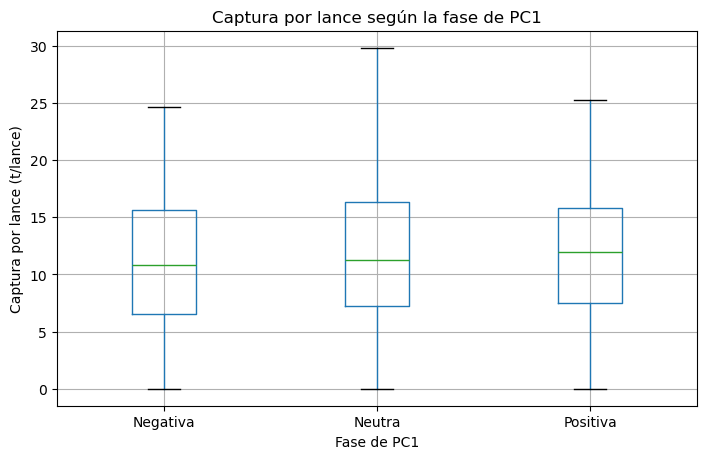

In [58]:
# Comparar la captura por lance entre fases
datos_fases.boxplot(
    column="captura_por_lance",
    by="fase",
    figsize=(8, 5),
    showfliers=False
)

plt.xlabel("Fase de PC1")
plt.ylabel("Captura por lance (t/lance)")
plt.title("Captura por lance según la fase de PC1")
plt.suptitle("")
plt.show()

In [ ]:
#no demuestra que las fases sean iguales ni que sean diferente estadísticamente

In [59]:
# Comparar las fases, ajustando por mes y tendencia temporal
modelo_fases = smf.ols(
    "captura_por_lance ~ C(fase, Treatment(reference='Negativa'))"
    " + C(Month) + tiempo_anios",
    data=datos_fases
).fit()

# Mostrar las diferencias respecto a la fase negativa
print(modelo_fases.params.filter(like="fase"))

C(fase, Treatment(reference='Negativa'))[T.Neutra]     -0.308254
C(fase, Treatment(reference='Negativa'))[T.Positiva]    0.019091
dtype: float64


In [60]:
# Identificar los meses calendario
meses_fases = (
    (datos_fases["Year"] - 1960) * 12
    + datos_fases["Month"] - 1
)

# Calcular la incertidumbre con errores HAC
fases_robusto = modelo_fases.get_robustcov_results(
    cov_type="hac-groupsum",
    time=meses_fases.to_numpy(),
    maxlags=12,
    use_correction="hac",
    df_correction=False,
    use_t=False
)

# Mostrar solo las comparaciones entre fases
resultados_fases = pd.DataFrame({
    "diferencia": fases_robusto.params,
    "IC95_inferior": fases_robusto.conf_int()[:, 0],
    "IC95_superior": fases_robusto.conf_int()[:, 1],
    "valor_p": fases_robusto.pvalues
}, index=modelo_fases.model.exog_names)

print(resultados_fases.filter(like="fase", axis=0).round(3))

                                                    diferencia  IC95_inferior  \
C(fase, Treatment(reference='Negativa'))[T.Neutra]      -0.308         -2.148   
C(fase, Treatment(reference='Negativa'))[T.Posi...       0.019         -2.355   

                                                    IC95_superior  valor_p  
C(fase, Treatment(reference='Negativa'))[T.Neutra]          1.531    0.743  
C(fase, Treatment(reference='Negativa'))[T.Posi...          2.393    0.987  


# No se encontraron diferencias estadísticamente significativas en la captura por lance de las fases positiva y neutra de PC1 respecto a la fase negativa, al considerar el mes del año y la tendencia temporal.


# MODELO PARA ANOMALÍAS LOCALES

In [12]:
import pandas as pd
import xarray as xr

In [13]:
datos = pd.read_csv("PublicPSTunaSetType.csv")

atun_domo = datos[
    (datos["LatC1"] >= 7) &
    (datos["LatC1"] <= 11) &
    (datos["LonC1"] >= -93) &
    (datos["LonC1"] <= -87)
].copy()

atun_domo.head()

,Year,Month,SetType,LatC1,LonC1,NumSets,ALB,BET,BKJ,BZX,FRZ,PBF,SKJ,TUN,YFT
510,1960,4,DEL,10.5,-89.5,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,86.1
581,1960,5,DEL,9.5,-90.5,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,63.5
582,1960,5,DEL,9.5,-89.5,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,18.1
585,1960,5,DEL,10.5,-90.5,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.7
586,1960,5,DEL,10.5,-89.5,14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,399.1


In [14]:
archivo_nc = "cmems_obs-ins_glo_phy-temp-sal_my_cora-oa_P1M_TEMP_96.00W-77.00W_2.10N-16.00N_1.00m_1960-01-01-2025-06-01.nc"

ds = xr.open_dataset(archivo_nc)

print(ds)

<xarray.Dataset> Size: 17MB
Dimensions:    (time: 786, depth: 1, latitude: 140, longitude: 39)
Coordinates:
  * time       (time) datetime64[ns] 6kB 1960-01-01 1960-02-01 ... 2025-06-01
  * depth      (depth) float32 4B 1.0
  * latitude   (latitude) float64 1kB 2.1 2.2 2.3 2.4 ... 15.7 15.8 15.9 16.0
  * longitude  (longitude) float64 312B -96.0 -95.5 -95.0 ... -78.0 -77.5 -77.0
Data variables:
    TEMP       (time, depth, latitude, longitude) float32 17MB ...
Attributes: (12/22)
    Conventions:               CF-1.4
    analysis_name:             OA_CORA5.2_
    comment:                   V8.0 reference climatology and analysis parame...
    creation_date:             20260511T073736
    data_manager:              Tanguy Szekely
    easternmost_longitude:     179.5
    ...                        ...
    southernmost_latitude:     -77.010475
    start_date:                2025-06-15
    stop_date:                 2025-06-15
    title:                     Global Ocean - Coriolis Observa

In [15]:
# Agrupar la pesca por año y mes
pesca_mensual = atun_domo.groupby(
    ["Year", "Month"]
)[["YFT", "NumSets"]].sum().reset_index()

# Mostrar las primeras seis filas
pesca_mensual.head(6)

,Year,Month,YFT,NumSets
0,1960,4,86.1,5
1,1960,5,537.0,23
2,1960,7,0.0,1
3,1960,9,29.0,1
4,1960,10,8.1,4
5,1961,3,282.1,25


In [16]:
# para calculo de captura por lance Dividir la captura mensual entre los lances del mes
pesca_mensual["captura_por_lance"] = (
    pesca_mensual["YFT"] / pesca_mensual["NumSets"]
)

pesca_mensual.head(6)

,Year,Month,YFT,NumSets,captura_por_lance
0,1960,4,86.1,5,17.220000
1,1960,5,537.0,23,23.347826
2,1960,7,0.0,1,0.000000
3,1960,9,29.0,1,29.000000
4,1960,10,8.1,4,2.025000
5,1961,3,282.1,25,11.284000


In [17]:
# Crear una fecha con el año y el mes
pesca_mensual["fecha"] = pd.to_datetime(
    dict(
        year=pesca_mensual["Year"],
        month=pesca_mensual["Month"],
        day=1
    )
)

pesca_mensual.head(6)

,Year,Month,YFT,NumSets,captura_por_lance,fecha
0,1960,4,86.1,5,17.220000,1960-04-01
1,1960,5,537.0,23,23.347826,1960-05-01
2,1960,7,0.0,1,0.000000,1960-07-01
3,1960,9,29.0,1,29.000000,1960-09-01
4,1960,10,8.1,4,2.025000,1960-10-01
5,1961,3,282.1,25,11.284000,1961-03-01


In [18]:
# Seleccionar la temperatura a 1 metro dentro del Domo para que la temp corresponde con la misma área de pesca
temperatura_domo = ds["TEMP"].isel(depth=0).sel(
    latitude=slice(7 - 0.000001, 11 + 0.000001),
    longitude=slice(-93, -87)
)

print(temperatura_domo)

<xarray.DataArray 'TEMP' (time: 786, latitude: 41, longitude: 13)> Size: 2MB
[418938 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 6kB 1960-01-01 1960-02-01 ... 2025-06-01
  * latitude   (latitude) float64 328B 7.0 7.1 7.2 7.3 ... 10.7 10.8 10.9 11.0
  * longitude  (longitude) float64 104B -93.0 -92.5 -92.0 ... -88.0 -87.5 -87.0
    depth      float32 4B 1.0
Attributes:
    long_name:      Temperature
    regrid_method:  bilinear
    standard_name:  sea_water_temperature
    units:          degree_Celsius
    valid_max:      40.0
    valid_min:      -3.0


# únicamente el Domo, con 786 meses, 41 latitudes y 13 longitudes, a 1 metro de profundidad.

In [20]:
# Contar los valores de temperatura que faltan
faltantes = temperatura_domo.isnull().sum().item()

print("Valores faltantes:", faltantes)

Valores faltantes: 0


In [21]:
import numpy as np
import xarray as xr

# Crear los pesos según la latitud y la longitud
peso_lat = np.cos(np.deg2rad(temperatura_domo.latitude))
peso_lon = xr.ones_like(temperatura_domo.longitude)

# Las celdas de los bordes aportan la mitad de su ancho
peso_lat[[0, -1]] = peso_lat[[0, -1]] / 2
peso_lon[[0, -1]] = peso_lon[[0, -1]] / 2

# Calcular la temperatura promedio de cada mes
temperatura_mensual = temperatura_domo.weighted(
    peso_lat * peso_lon
).mean(dim=["latitude", "longitude"])

# Mostrar los primeros seis meses
temperatura_mensual.head(6)

<xarray.DataArray 'TEMP' (time: 6)> Size: 48B
array([25.03768985, 26.55974183, 27.66086108, 28.2825275 , 29.24275402,
       28.02665992])
Coordinates:
  * time     (time) datetime64[ns] 48B 1960-01-01 1960-02-01 ... 1960-06-01
    depth    float32 4B 1.0
Attributes:
    long_name:      Temperature
    regrid_method:  bilinear
    standard_name:  sea_water_temperature
    units:          degree_Celsius
    valid_max:      40.0
    valid_min:      -3.0

In [22]:
# Seleccionar el período de referencia
temperatura_referencia = temperatura_mensual.sel(
    time=slice("1991-01-01", "2020-12-31")
)

print("Meses de referencia:", temperatura_referencia.sizes["time"])

Meses de referencia: 360


In [23]:
# Calcular los 12 promedios mensuales de referencia
climatologia_domo = temperatura_referencia.groupby(
    "time.month"
).mean(dim="time")

print(climatologia_domo)

<xarray.DataArray 'TEMP' (month: 12)> Size: 96B
array([26.54287709, 27.08120375, 27.42116545, 28.67366783, 29.2292376 ,
       28.54144942, 28.1813211 , 28.04033768, 28.00683767, 27.49222076,
       27.50784521, 26.89848499])
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    depth    float32 4B 1.0
Attributes:
    long_name:      Temperature
    regrid_method:  bilinear
    standard_name:  sea_water_temperature
    units:          degree_Celsius
    valid_max:      40.0
    valid_min:      -3.0


In [24]:
# Calcular las anomalías mensuales de temperatura
anomalia_temperatura = (
    temperatura_mensual.groupby("time.month") - climatologia_domo
)

# Mostrar los primeros seis meses
anomalia_temperatura.head(6)

<xarray.DataArray 'TEMP' (time: 6)> Size: 48B
array([-1.50518724, -0.52146192,  0.23969563, -0.39114033,  0.01351642,
       -0.51478949])
Coordinates:
  * time     (time) datetime64[ns] 48B 1960-01-01 1960-02-01 ... 1960-06-01
    depth    (time) float32 24B 1.0 1.0 1.0 1.0 1.0 1.0
    month    (time) int64 48B 1 2 3 4 5 6
Attributes:
    long_name:      Temperature
    regrid_method:  bilinear
    standard_name:  sea_water_temperature
    units:          degree_Celsius
    valid_max:      40.0
    valid_min:      -3.0

In [25]:
# una vez calculadas las anomalias hay que hacer la tabla con fecha y anomalia
# Convertir las anomalías en una tabla
tabla_temperatura = anomalia_temperatura.to_dataframe(
    name="anomalia_c"
).reset_index()

# Conservar la fecha y la anomalía
tabla_temperatura = tabla_temperatura[
    ["time", "anomalia_c"]
].rename(columns={"time": "fecha"})

tabla_temperatura.head(6)

,fecha,anomalia_c
0,1960-01-01,-1.505187
1,1960-02-01,-0.521462
2,1960-03-01,0.239696
3,1960-04-01,-0.391140
4,1960-05-01,0.013516
5,1960-06-01,-0.514789


In [27]:
# Unir tablas de pesca y temp por fecha
datos_analisis = pesca_mensual.merge(
    tabla_temperatura,
    on="fecha",
    how="inner",
    validate="one_to_one"
)

datos_analisis.head(6)

,Year,Month,YFT,NumSets,captura_por_lance,fecha,anomalia_c
0,1960,4,86.1,5,17.220000,1960-04-01,-0.391140
1,1960,5,537.0,23,23.347826,1960-05-01,0.013516
2,1960,7,0.0,1,0.000000,1960-07-01,-0.797417
3,1960,9,29.0,1,29.000000,1960-09-01,-0.151440
4,1960,10,8.1,4,2.025000,1960-10-01,-1.661787
5,1961,3,282.1,25,11.284000,1961-03-01,-0.257061


In [28]:
# Comprobación de la cantidad de meses y el período
print("Meses coincidentes:", len(datos_analisis))
print("Primera fecha:", datos_analisis["fecha"].min())
print("Última fecha:", datos_analisis["fecha"].max())

Meses coincidentes: 720
Primera fecha: 1960-04-01 00:00:00
Última fecha: 2025-05-01 00:00:00


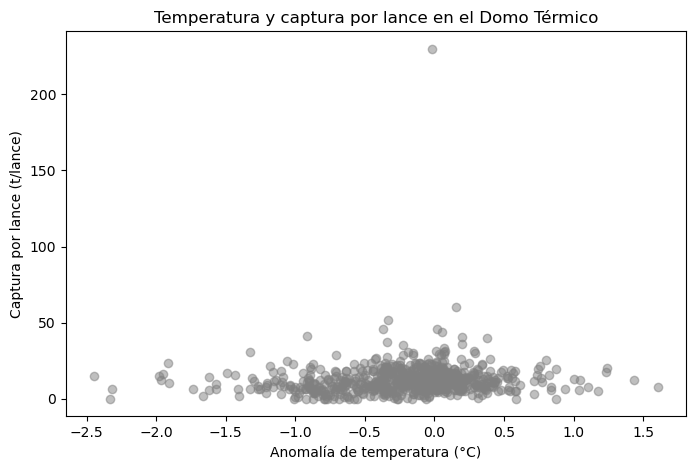

In [29]:
# gráfico de dispersión para observar cómo se relacionan ambas variables. Cada punto corresponde a un mes.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    datos_analisis["anomalia_c"],
    datos_analisis["captura_por_lance"],
    color="gray",
    alpha=0.5
)

plt.xlabel("Anomalía de temperatura (°C)")
plt.ylabel("Captura por lance (t/lance)")
plt.title("Temperatura y captura por lance en el Domo Térmico")

plt.show()


# En el gráfico se ve una amplia dispersión de la captura por lance y no permite identificar una relación lineal clara con las anomalías de temperatura. El valor extremo cercano a 230 t/lance que requiere revisión.

In [30]:
# Mostrar el mes con la mayor captura por lance (Al parecer el dato está bien desde la base de datos)
datos_analisis.nlargest(1, "captura_por_lance")[
    ["fecha", "YFT", "NumSets", "captura_por_lance", "anomalia_c"]
]

,fecha,YFT,NumSets,captura_por_lance,anomalia_c
635,2017-08-01,230.0,1,230.0,-0.018554


In [31]:
# Calcular la correlación de Pearson
correlacion = datos_analisis["anomalia_c"].corr(
    datos_analisis["captura_por_lance"]
)

print("Correlación de Pearson:", round(correlacion, 3))

Correlación de Pearson: 0.101


# esta correlación es positiva y débil, demuestra que hay una asociación pequeña entre meses mas cálidos y aumento de captura, se probara eliminando el dato extremo del 2017

In [32]:
# Crear una tabla temporal sin agosto de 2017
sin_extremo = datos_analisis[
    datos_analisis["fecha"] != "2017-08-01"
]

# Calcular nuevamente la correlación
correlacion_sin_extremo = sin_extremo["anomalia_c"].corr(
    sin_extremo["captura_por_lance"]
)

print("Con todos los meses:", round(correlacion, 3))
print("Sin agosto de 2017:", round(correlacion_sin_extremo, 3))

Con todos los meses: 0.101
Sin agosto de 2017: 0.133


In [33]:
# Calcular la correlación de Spearman (menos sensible a esa variación)
spearman = datos_analisis["anomalia_c"].corr(
    datos_analisis["captura_por_lance"],
    method="spearman"
)

print("Correlación de Spearman:", round(spearman, 3))

Correlación de Spearman: 0.166


In [34]:
# Resumir las anomalías y la captura por lance
datos_analisis[
    ["anomalia_c", "captura_por_lance"]
].describe()

,anomalia_c,captura_por_lance
count,720.000000,720.000000
mean,-0.206181,12.584583
std,0.516350,11.073990
min,-2.446799,0.000000
25%,-0.443439,7.183198
50%,-0.116955,11.294500
75%,0.075307,16.319886
max,1.605446,230.000000


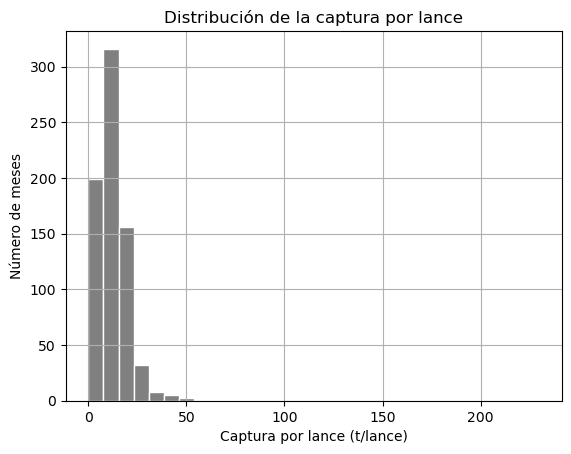

In [35]:
import matplotlib.pyplot as plt

datos_analisis["captura_por_lance"].hist(
    bins=30,
    color="gray",
    edgecolor="white"
)

plt.xlabel("Captura por lance (t/lance)")
plt.ylabel("Número de meses")
plt.title("Distribución de la captura por lance")
plt.show()

# la mayoría de los meses se concentra en capturas por lance bajas o moderadas, y pocos presentan valores altos.

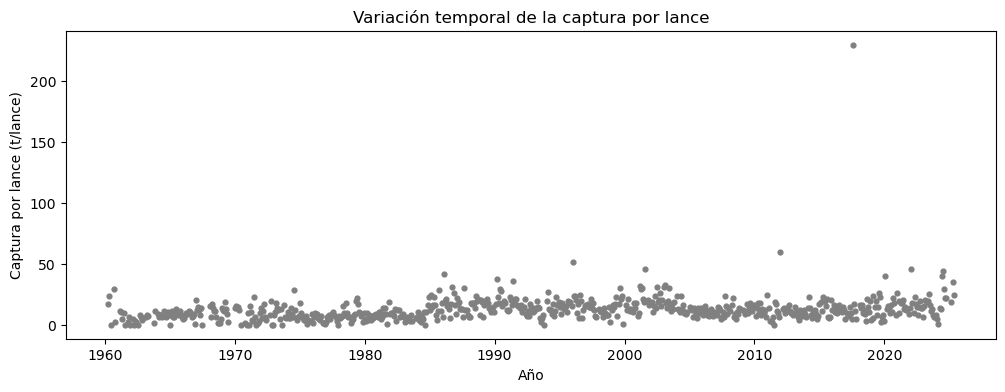

In [36]:
# Graficar la captura por lance a través del tiempo
plt.figure(figsize=(12, 4))

plt.scatter(
    datos_analisis["fecha"],
    datos_analisis["captura_por_lance"],
    color="gray",
    s=12
)

plt.xlabel("Año")
plt.ylabel("Captura por lance (t/lance)")
plt.title("Variación temporal de la captura por lance")
plt.show()

# los cambios podrían ser también por cambios en la pesca (nuevas tecnologías y autonomía de los barcos), no se pueden atribuir solo a temp

In [37]:
# Calcular la mediana de captura por lance para cada mes
mediana_por_mes = datos_analisis.groupby(
    "Month"
)["captura_por_lance"].median()

print(mediana_por_mes)

Month
1     11.142857
2     11.422085
3     12.515880
4     13.900000
5     12.869907
6     11.669945
7     10.396003
8     10.647059
9     11.877456
10    10.432037
11    10.448718
12     9.050000
Name: captura_por_lance, dtype: float64


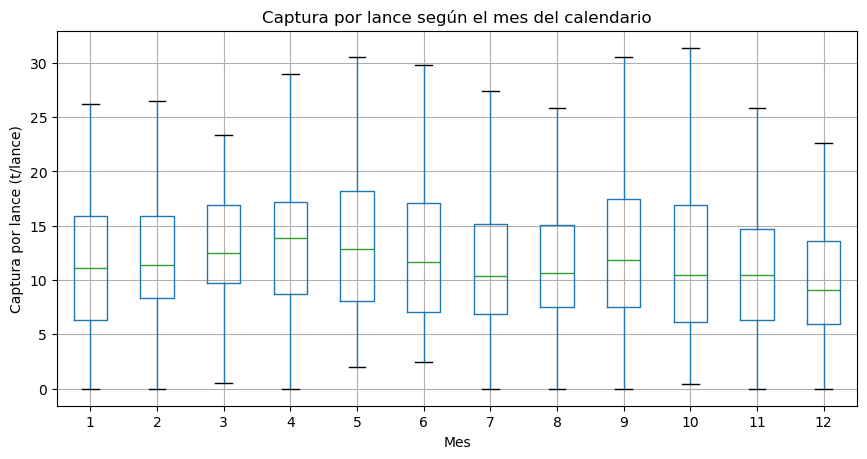

In [38]:
# Comparar la distribución de captura por lance entre meses
datos_analisis.boxplot(
    column="captura_por_lance",
    by="Month",
    figsize=(10, 5),
    showfliers=False
)

plt.xlabel("Mes")
plt.ylabel("Captura por lance (t/lance)")
plt.title("Captura por lance según el mes del calendario")
plt.suptitle("")
plt.show()

# La captura por lance tiene distribuciones solapadas entre meses del calendario, no se ve un patrón estacional marcado a simple vista. Se observaron diferencias moderadas en las medianas y variabilidad dentro de cada mes.

# primera regresión lineal simple para estimar cuánto cambia la captura por lance cuando la anomalía aumenta 1 °C.

In [39]:
import statsmodels.formula.api as smf

# Ajustar la regresión con todos los meses
modelo_simple = smf.ols(
    "captura_por_lance ~ anomalia_c",
    data=datos_analisis
).fit()

# Mostrar los coeficientes y el R²
print(modelo_simple.params)
print("R²:", modelo_simple.rsquared)

Intercept     13.029003
anomalia_c     2.155484
dtype: float64
R²: 0.010101106298497586


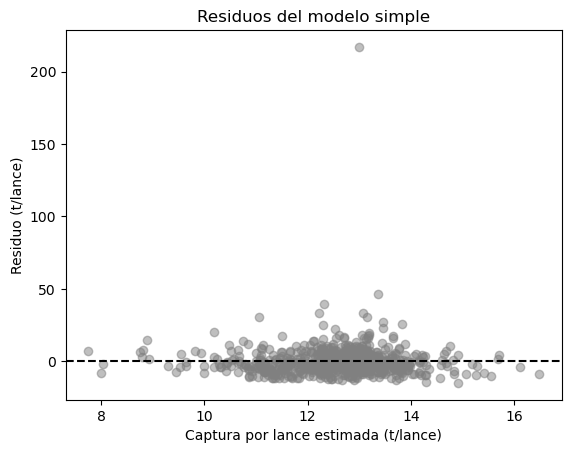

In [40]:
# Comparar los valores estimados con los residuos
plt.scatter(
    modelo_simple.fittedvalues,
    modelo_simple.resid,
    color="gray",
    alpha=0.5
)

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Captura por lance estimada (t/lance)")
plt.ylabel("Residuo (t/lance)")
plt.title("Residuos del modelo simple")
plt.show()

In [41]:
# Organizar los residuos por fecha
residuos = pd.Series(
    modelo_simple.resid.to_numpy(),
    index=datos_analisis["fecha"]
).sort_index()

# Mantener los meses ausentes como valores faltantes
residuos = residuos.asfreq("MS")

# Calcular la correlación entre meses consecutivos
print("Autocorrelación a un mes:", residuos.autocorr(lag=1))

Autocorrelación a un mes: 0.16275358675469995


In [42]:
# Revisar la autocorrelación a distintas distancias temporales
for meses in [1, 2, 3, 6, 12]:
    valor = residuos.autocorr(lag=meses)
    print(f"Rezago de {meses} meses: {valor:.3f}")

Rezago de 1 meses: 0.163
Rezago de 2 meses: 0.114
Rezago de 3 meses: 0.094
Rezago de 6 meses: 0.074
Rezago de 12 meses: 0.079


In [43]:
# Expresar el tiempo transcurrido en años desde 1960
datos_analisis["tiempo_anios"] = (
    datos_analisis["Year"] - 1960
    + (datos_analisis["Month"] - 1) / 12
)

datos_analisis[["fecha", "tiempo_anios"]].head(6)

,fecha,tiempo_anios
0,1960-04-01,0.250000
1,1960-05-01,0.333333
2,1960-07-01,0.500000
3,1960-09-01,0.666667
4,1960-10-01,0.750000
5,1961-03-01,1.166667


# ajuste de la regresión incorporando el mes del calendario y la tendencia temporal

In [44]:
# Ajustar por temperatura, mes del año y paso del tiempo
modelo_ajustado = smf.ols(
    "captura_por_lance ~ anomalia_c + C(Month) + tiempo_anios",
    data=datos_analisis
).fit()

# Mostrar la pendiente de temperatura y el R²
print("Pendiente de temperatura:", modelo_ajustado.params["anomalia_c"])
print("R² del modelo:", modelo_ajustado.rsquared)

Pendiente de temperatura: -1.0612249278912178
R² del modelo: 0.08093758965976128


In [46]:
# Crear una copia actualizada sin agosto de 2017
sin_extremo = datos_analisis[
    datos_analisis["fecha"] != "2017-08-01"
].copy()

# Ajustar el modelo con esa copia
modelo_ajustado_sin_extremo = smf.ols(
    "captura_por_lance ~ anomalia_c + C(Month) + tiempo_anios",
    data=sin_extremo
).fit()

print(
    "Pendiente sin agosto de 2017:",
    modelo_ajustado_sin_extremo.params["anomalia_c"]
)

Pendiente sin agosto de 2017: -0.7910443810978902


# el mes extremo influye en la magnitud, pero no determina por sí solo el signo negativo. se mantienen todos los meses en el modelo principal. 

In [47]:
# Identificar los meses calendario, conservando los huecos
mes_calendario = (
    (datos_analisis["Year"] - 1960) * 12
    + datos_analisis["Month"] - 1
)

# Calcular la incertidumbre robusta del modelo
modelo_robusto = modelo_ajustado.get_robustcov_results(
    cov_type="hac-groupsum",
    time=mes_calendario.to_numpy(),
    maxlags=12,
    use_correction="hac",
    df_correction=False,
    use_t=False
)

# Mostrar los resultados de la anomalía de temperatura
posicion = modelo_ajustado.model.exog_names.index("anomalia_c")

print("Pendiente:", modelo_robusto.params[posicion])
print("Intervalo del 95 %:", modelo_robusto.conf_int()[posicion])
print("Valor p:", modelo_robusto.pvalues[posicion])

Pendiente: -1.0612249278912178
Intervalo del 95 %: [-2.48850473  0.36605487]
Valor p: 0.14503594787228558


# No se encontró una relación clara entre las anomalías de temperatura y la captura por lance del mismo mes, considerando el mes del año y los cambios a lo largo del tiempo.